In [5]:
import zipfile

In [6]:
zipfile.ZipFile("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/garbage.zip").extractall("/content/garbage/")

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import pandas as pd
import hashlib
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from pathlib import Path
from google.colab import drive
from tensorflow.keras import layers,models
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import math
from sklearn.model_selection import train_test_split
import os

# EDA

## tahap 1 (jumlah file)

In [9]:
root = Path("/content/garbage/original")

records = []


for path in sorted(root.rglob("*")):
    # print(path.parent.name)
    if path.is_file():
          record = {
            "class" : path.parent.name,
            "filename": path.name,
            "extension": path.suffix.lower(),
            "path": path,
            "format": None,
            "mode" : None,
            "width" : None,
            "height" : None,
            "error" : None,
            "is_image" : False
            }

          try:
              with Image.open(path) as img:
                img.load()
                record["width"], record["height"] = img.size
                record["format"] = img.format
                record["mode"] = img.mode
                record["is_image"] = True

                  # print("success")
          except Exception as e:
                  record['error'] = str(e)
          records.append(record)

df = pd.DataFrame(records)
df[["width", "height"]] = df[["width", "height"]].astype("Int64")
print(df.shape)
display(df.head())
df.to_csv("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/EDA_1.csv", index=False)


(12259, 10)


,class,filename,extension,path,format,mode,width,height,error,is_image
0,battery,battery_1.jpg,.jpg,/content/garbage/original/battery/battery_1.jpg,JPEG,RGB,225,225,None,True
1,battery,battery_10.jpg,.jpg,/content/garbage/original/battery/battery_10.jpg,JPEG,RGB,259,194,None,True
2,battery,battery_100.jpg,.jpg,/content/garbage/original/battery/battery_100.jpg,JPEG,RGB,215,193,None,True
3,battery,battery_101.jpg,.jpg,/content/garbage/original/battery/battery_101.jpg,JPEG,RGB,259,194,None,True
4,battery,battery_102.jpg,.jpg,/content/garbage/original/battery/battery_102.jpg,JPEG,RGB,400,126,None,True


Jumlah Semua file (data) : 12259


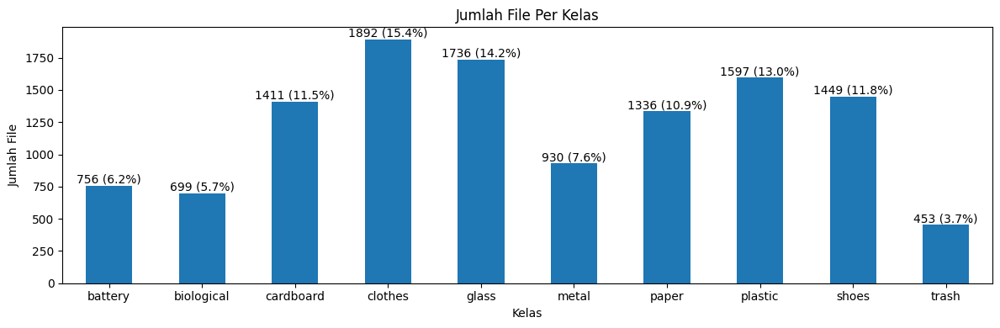

In [10]:

counts = df["class"].value_counts().sort_index()
total = counts.sum()
print("Jumlah Semua file (data) :" , total )

ax = counts.plot(kind="bar", rot=0, figsize=(12, 4))
ax.bar_label(ax.containers[0],
             labels=[f"{v} ({v / total * 100:.1f}%)" for v in counts.values])
plt.title("Jumlah File Per Kelas")
plt.xlabel("Kelas")
plt.ylabel("Jumlah File")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/total_data_per_folder.png", dpi=150, bbox_inches="tight")
plt.show()

## tahap 2 (duplikasi)

In [11]:
def file_md5(value):
    return hashlib.md5(Path(value).read_bytes()).hexdigest()

df["md5"] = df["path"].apply(file_md5)


df["md5_duplicate"] = df.duplicated(subset="md5", keep=False) & df["is_image"]


df["delete_dup"] = df.duplicated(subset="md5", keep="first") & df["is_image"]
# display(df.head())
# g = df[df["md5_duplicate"]].groupby("md5")


display(df.shape)
df.to_csv("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/EDA_2.csv", index=False)


(12259, 13)

## Tahap 3 (ukuran gambar)

### cek ukuran

In [12]:
img_df = df[df["is_image"]].copy()
img_df["luas"] = img_df["width"] * img_df["height"]

display(img_df[["width", "height"]].describe().round(1))
display(img_df["width"].value_counts().head())
display(img_df["height"].value_counts().head())

display(pd.crosstab(img_df["width"] < 224, img_df["height"] < 224,
                    rownames=["lebar < 224"], colnames=["tinggi < 224"],
                    margins=True))

display(pd.crosstab(img_df["format"], img_df["mode"]))
display(pd.crosstab(img_df["class"], img_df["mode"]))

,width,height
count,12259.0,12259.0
mean,440.1,430.6
std,329.6,361.8
min,51.0,71.0
25%,252.0,225.0
50%,400.0,384.0
75%,512.0,533.0
max,7786.0,6283.0


,count
width,
512,2220
400,2019
225,1390
474,537
259,395


,count
height,
384,2218
225,1493
533,1028
534,504
400,445


tinggi < 224,False,True,All
lebar < 224,,,
False,8927,2167,11094
True,949,216,1165
All,9876,2383,12259


mode,RGB
format,
JPEG,12252
MPO,5
WEBP,2


mode,RGB
class,
battery,756
biological,699
cardboard,1411
clothes,1892
glass,1736
metal,930
paper,1336
plastic,1597
shoes,1449


### sample gambar piksel kecil

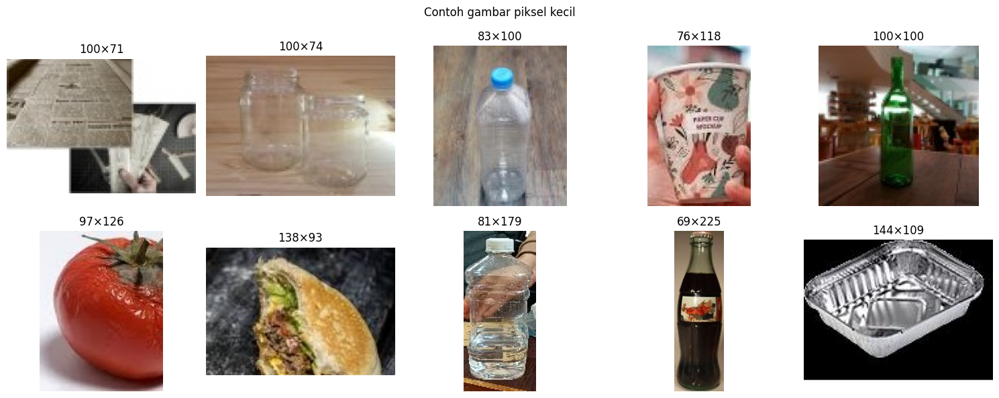

In [13]:

terkecil = img_df.nsmallest(10, "luas")
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, (_, row) in zip(axes.flat, terkecil.iterrows()):
    ax.imshow(Image.open(row["path"]))
    ax.set_title(f'{row["width"]}×{row["height"]}')
    ax.axis("off")


fig.suptitle("Contoh gambar piksel kecil")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/sample/contoh_gambar_piksel_kecil.png", dpi=150, bbox_inches="tight")
plt.show()

### sample gambar piksel kecil diperbesar menjadi 224 piksel

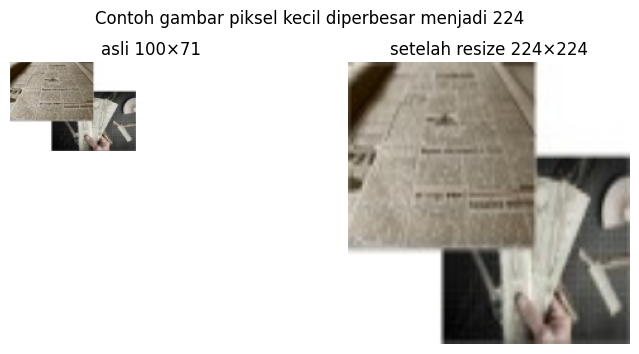

In [14]:
row = terkecil.iloc[0]
arr = np.array(Image.open(row["path"]).convert("RGB"))
besar = tf.image.resize(arr, (224, 224))
besar = tf.cast(besar, tf.uint8)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(arr)
axes[0].set_xlim(0, 224); axes[0].set_ylim(224, 0)
axes[0].set_title(f'asli {row["width"]}×{row["height"]}')
axes[1].imshow(besar)
axes[1].set_title("setelah resize 224×224")
for ax in axes:
    ax.axis("off")
fig.suptitle("Contoh gambar piksel kecil diperbesar menjadi 224")
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/sample/contoh_gambar_piksel_kecil_diperbesar.png", dpi=150, bbox_inches="tight")
plt.show()


## tahap 4 (sample 16 gambar)

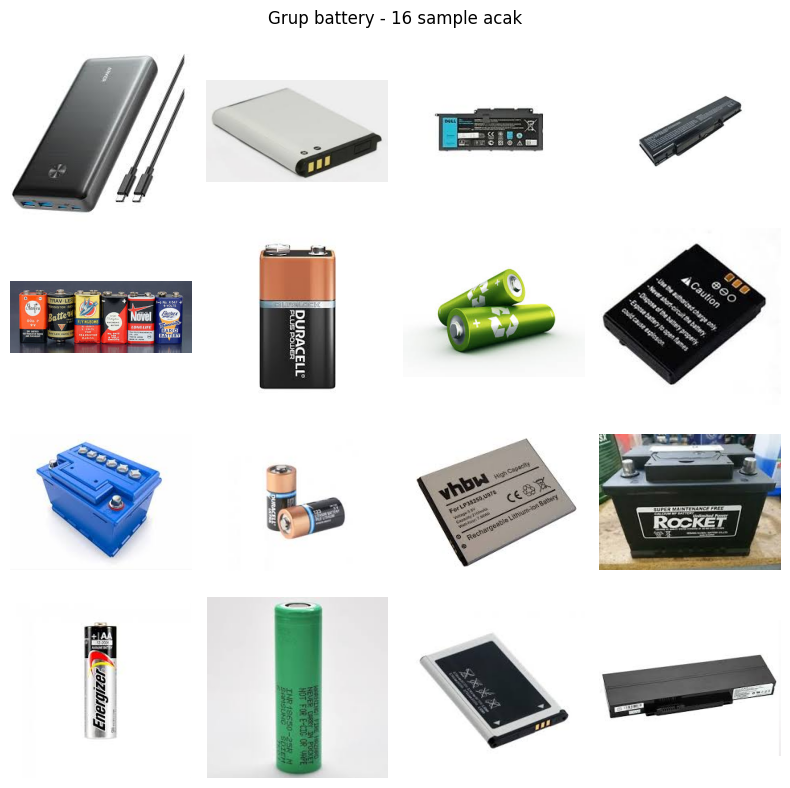

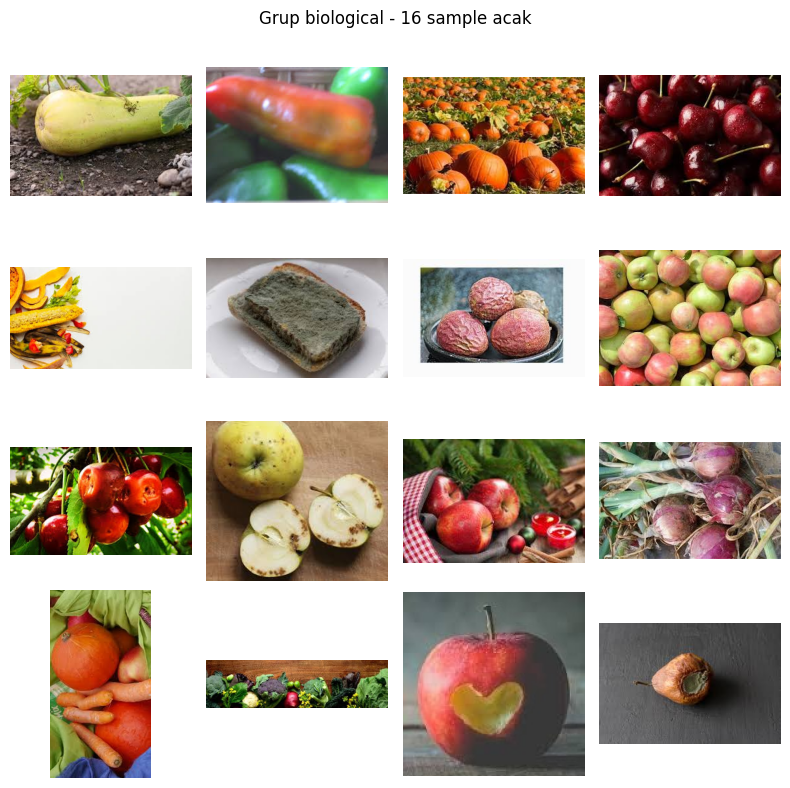

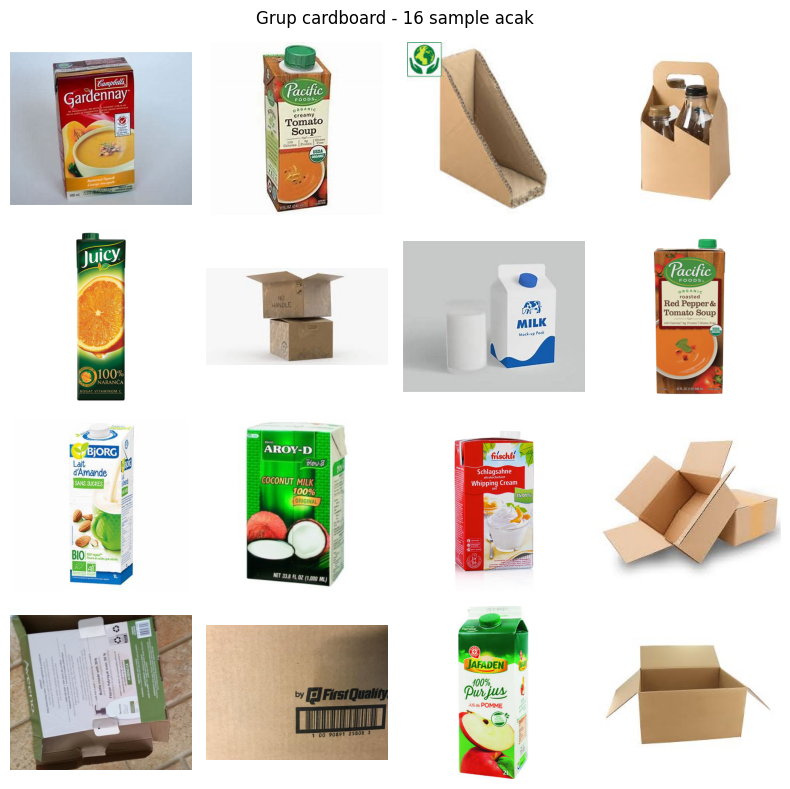

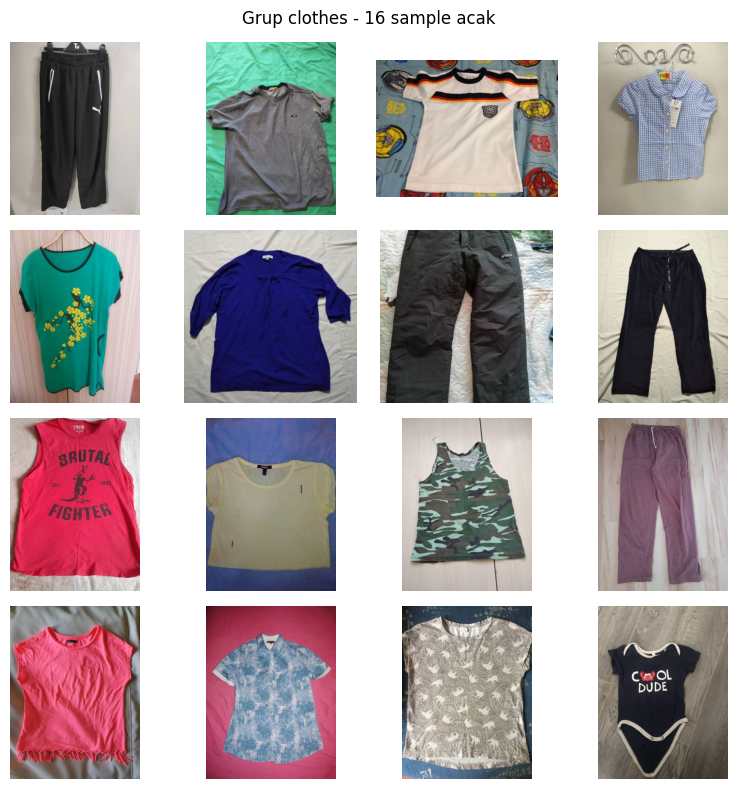

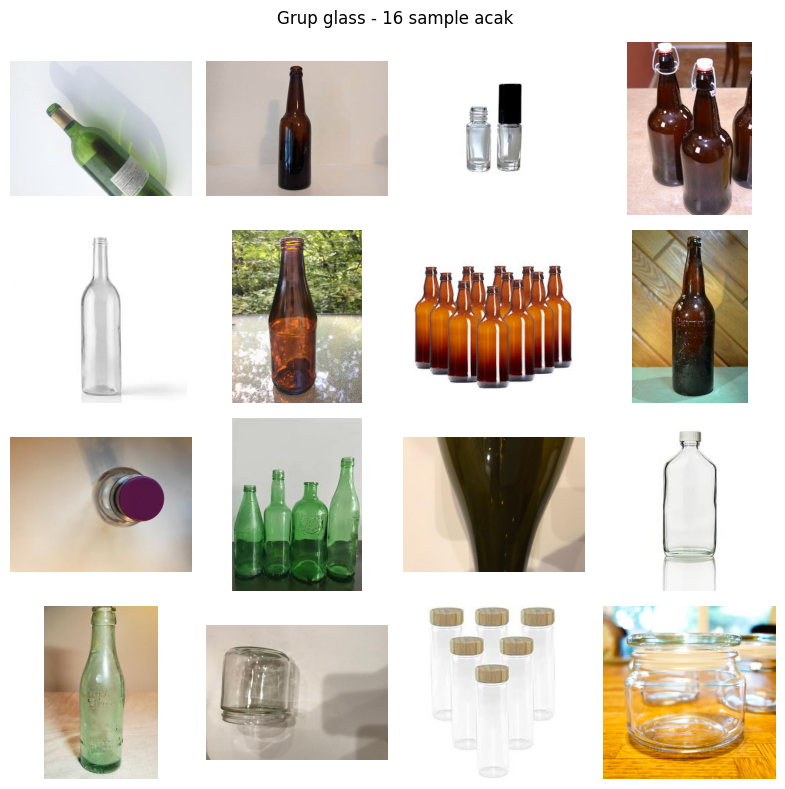

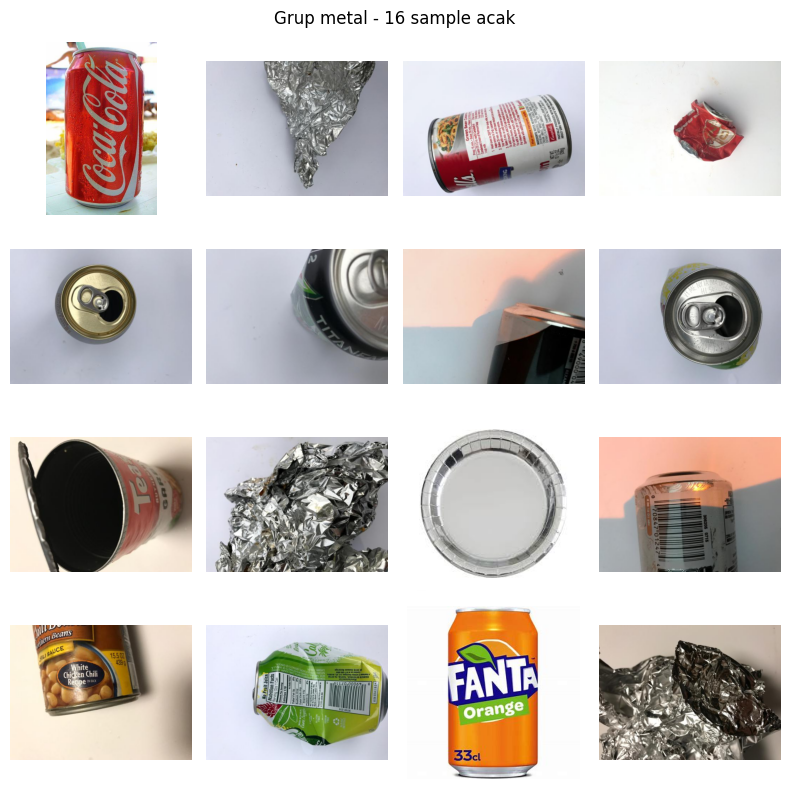

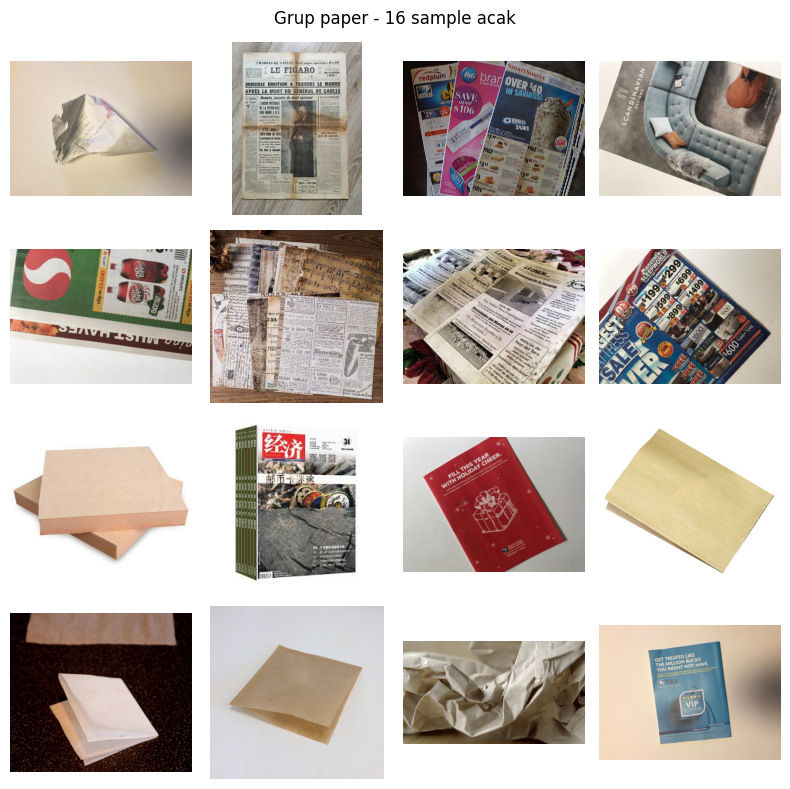

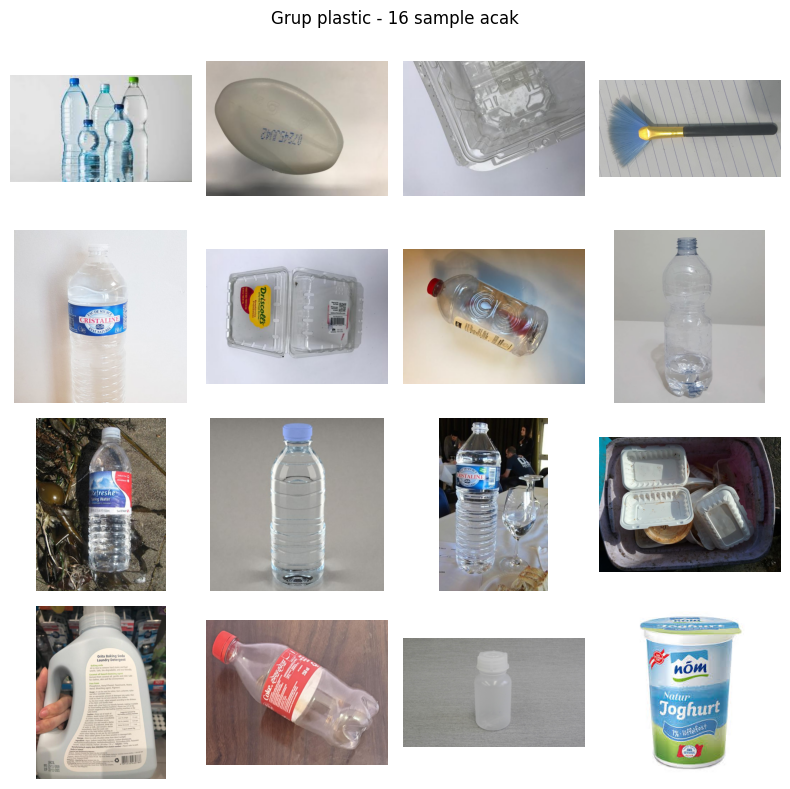

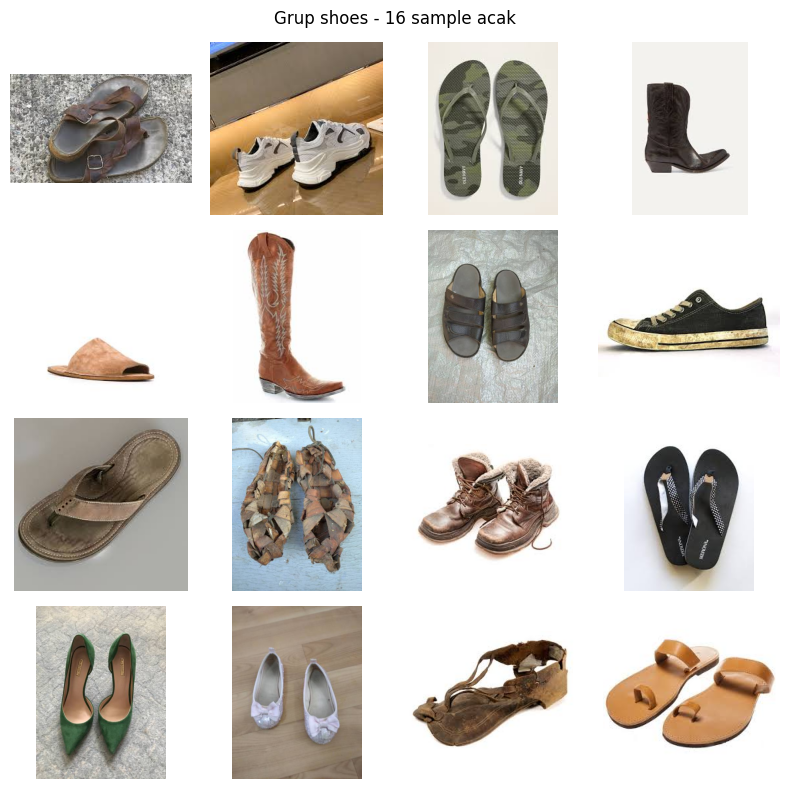

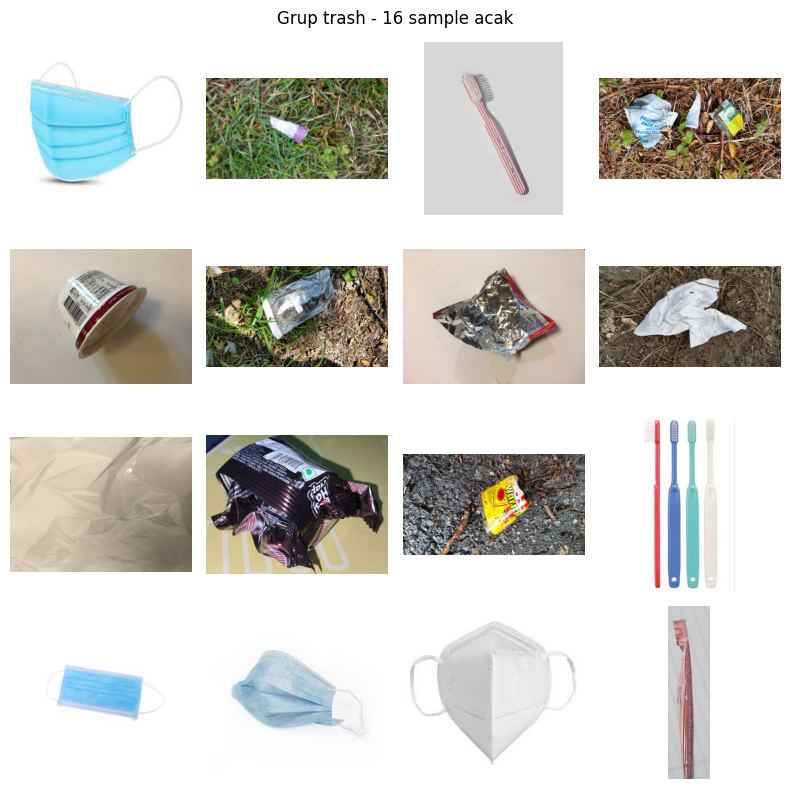

In [15]:

for c in sorted(df["class"].unique()):
    sample = df[df["class"] == c].sample(16, random_state=42)
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))   # 4x4 grid

    for ax, p in zip(axes.flat, sample["path"]):
        ax.imshow(Image.open(p))
        ax.axis("off")

    fig.suptitle(f"Grup {c} - 16 sample acak")
    plt.tight_layout()
    plt.savefig(f"/content/drive/MyDrive/Kuliah/UTS_AI_garbage/sample/sample_{c}.png", dpi=150, bbox_inches="tight")
    plt.show()

## tahap 5 (ringkasan)

In [16]:
image_ext = [".jpg", ".jpeg", ".png", ".webp"]
summary_jumlah_file = pd.DataFrame({
    "Metrik": ["Total file",
               "Gambar valid",
               "Format selain JPEG (dibuang)",
               "File non-gambar",
               "File rusak"
               ],
    "Jumlah": [
        len(df),
        df["is_image"].sum(),
        (df["format"] != "JPEG").sum(),
        (~df["extension"].isin(image_ext) & ~df["is_image"]).sum(),
        (df["extension"].isin(image_ext) & ~df["is_image"]).sum()
        ],
}).set_index("Metrik")

summary_duplikat_file = pd.DataFrame({
    "Metrik": ["Gambar dengan salinan sama",
               "Gambar duplikat dibuang"
               ],
    "Jumlah": [
        df['md5_duplicate'].sum(),
        df["delete_dup"].sum()
        ],
}).set_index("Metrik")

display(Markdown("### 1. Jumlah file"))
display(summary_jumlah_file)
display(Markdown("### 2. Duplikat"))
display(summary_duplikat_file)
display(Markdown("#### 2.1. Lokasi gambar duplikat"))
dup = df[df["delete_dup"]]
display(dup["class"].value_counts())
display(Markdown("### 3. Format gambar"))
s = pd.Series(df['format'])
display(s.value_counts().rename_axis("Format").reset_index(name="Jumlah"))
display(Markdown("#### 3.1. Ukuran gambar"))
display(img_df[["width", "height"]].describe().round(1))
display(Markdown("#### 3.2. Warna gambar"))
display(img_df["mode"].value_counts().rename_axis("Mode").reset_index(name="Jumlah"))

### 1. Jumlah file

,Jumlah
Metrik,
Total file,12259
Gambar valid,12259
Format selain JPEG (dibuang),7
File non-gambar,0
File rusak,0


### 2. Duplikat

,Jumlah
Metrik,
Gambar dengan salinan sama,0
Gambar duplikat dibuang,0


#### 2.1. Lokasi gambar duplikat

,count
class,


... (2 outputs left out)

#### 3.1. Ukuran gambar

,width,height
count,12259.0,12259.0
mean,440.1,430.6
std,329.6,361.8
min,51.0,71.0
25%,252.0,225.0
50%,400.0,384.0
75%,512.0,533.0
max,7786.0,6283.0


#### 3.2. Warna gambar

,Mode,Jumlah
0,RGB,12259


# preprocessing

### tahap 1 (bersihkan data dan buat label)

In [17]:

df["to_delete"] = ~df["is_image"] | df["delete_dup"] | (df["format"] != "JPEG")
df_clean = df[~df["to_delete"]].copy()

class_names = sorted(df_clean["class"].unique())
label_map = {name: i for i, name in enumerate(class_names)}
df_clean["label"] = df_clean["class"].map(label_map)

display(df_clean["class"].value_counts())



# print(len(df) - len(df_clean), df["to_delete"].sum())
# display(df_clean["label"].value_counts(dropna=False))
# display(pd.crosstab(df_clean["class"], df_clean["label"]))
# display(pd.crosstab(df_clean["split"], df_clean["class"], margins=True))

df.to_csv("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/EDA_final.csv", index=False)


,count
class,
clothes,1892
glass,1735
plastic,1595
shoes,1449
cardboard,1411
paper,1332
metal,930
battery,756
biological,699


### tahap 2 (seimbangkan data)

In [18]:
n_per_class = df_clean["class"].value_counts().min()
balanced = df_clean.groupby("class").sample(n=n_per_class, random_state=42)
print(balanced["class"].value_counts())


class
battery       453
biological    453
cardboard     453
clothes       453
glass         453
metal         453
paper         453
plastic       453
shoes         453
trash         453
Name: count, dtype: int64


### tahap 3 (split data)

In [19]:
TEST_RATIO = 0.15
VAL_RATIO = 0.15

rest_df, test_part = train_test_split(
    balanced, test_size=TEST_RATIO, stratify=balanced["class"], random_state=42)

val_of_rest = VAL_RATIO / (1 - TEST_RATIO)
train_part, val_part = train_test_split(
    rest_df, test_size=val_of_rest, stratify=rest_df["class"], random_state=42)

print(len(train_part), len(val_part), len(test_part))

3170 680 680


### tahap 4 (pre process gambar)

(32, 224, 224, 3) <dtype: 'float32'>
0.0 255.0
[1 4 8 6 7 2 2 0 0 0 6 8 0 7 8 0 4 4 9 8 5 0 3 1 6 6 9 5 2 8 5 9]
3170 680 680
100 22 22


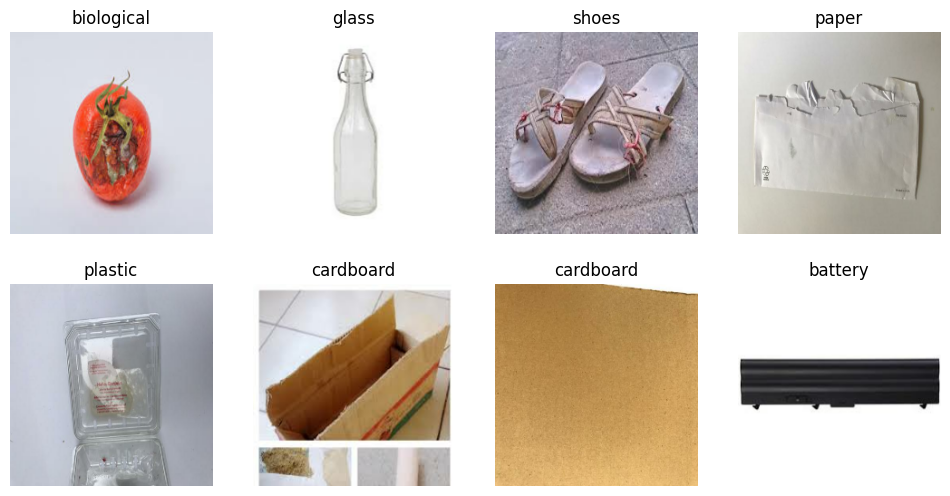

In [20]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(data, shuffle):
    ds = tf.data.Dataset.from_tensor_slices(
        (data["path"].astype(str).values, data["label"].values))
    if shuffle:
        ds = ds.shuffle(len(data), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_part, shuffle=True)
val_ds  = make_dataset(val_part, shuffle=False)
test_ds  = make_dataset(test_part, shuffle=False)

images, labels = next(iter(train_ds))
print(images.shape, images.dtype)
print(float(tf.reduce_min(images)), float(tf.reduce_max(images)))
print(labels.numpy())
print(len(train_part), len(val_part), len(test_part))
print(train_ds.cardinality().numpy(), val_ds.cardinality().numpy(), test_ds.cardinality().numpy())

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(class_names[int(lbl)])
    ax.axis("off")
plt.show()

### tahap 5 (augmentasi)

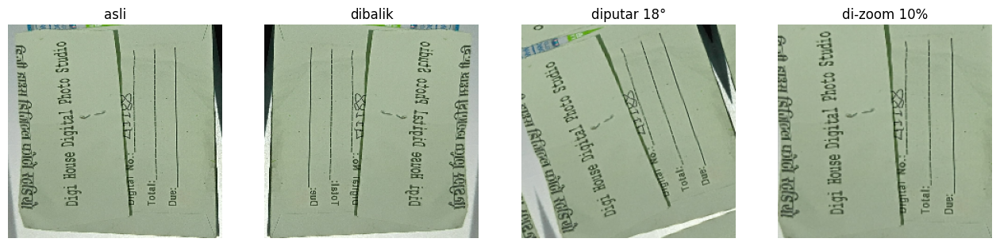

In [37]:
images, labels = next(iter(train_ds))
sample = images[:1]

examples = [
    ("asli", None),
    ("dibalik", lambda x, training: tf.image.flip_left_right(x)),
    ("diputar 18°", layers.RandomRotation((0.05, 0.05))),
    ("di-zoom 10%", layers.RandomZoom((-0.1, -0.1))),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, layer) in zip(axes, examples):
    out = sample if layer is None else layer(sample, training=True)
    ax.imshow(out[0].numpy().astype("uint8"))
    ax.set_title(name)
    ax.axis("off")
plt.show()

# MobileNetV2

## Training

In [22]:
tf.keras.utils.set_random_seed(42)
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

mobilenet_model = models.Sequential([
    layers.Input((224,224,3)),
    augment,
    layers.Rescaling(1/127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])
mobilenet_model.summary()

mobilenet_model.compile(optimizer="adam",
                        loss="sparse_categorical_crossentropy",
                        metrics=["accuracy"])

history_mobilenet = mobilenet_model.fit(train_ds,validation_data=val_ds, epochs=30)

display(pd.DataFrame(history_mobilenet.history))

mobilenet_model.save("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/model/mobilenet_v2.keras")
pd.DataFrame(history_mobilenet.history).to_csv("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/model/csv/history_mobilenet.csv", index=False)



9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - accuracy: 0.5404 - loss: 1.4136 - val_accuracy: 0.8294 - val_loss: 0.5586
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 14s 92ms/step - accuracy: 0.7675 - loss: 0.6892 - val_accuracy: 0.8662 - val_loss: 0.4311
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.8177 - loss: 0.5479 - val_accuracy: 0.8765 - val_loss: 0.3940
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.8413 - loss: 0.4844 - val_accuracy: 0.8779 - val_loss: 0.3862
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.8631 - loss: 0.4090 - val_accuracy: 0.8779 - val_loss: 0.3751
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.8587 - loss: 0.4140 - val_accuracy: 0.8853 - val_loss: 0.3550
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 89ms/step - accuracy: 0.8763 - loss: 0.3763 - val_accuracy: 0.8794 - val_loss: 0.3642
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.8748 - loss: 0.3567 - val_

,accuracy,loss,val_accuracy,val_loss
0,0.540379,1.413595,0.829412,0.558641
1,0.767508,0.689250,0.866176,0.431057
2,0.817666,0.547854,0.876471,0.394024
3,0.841325,0.484382,0.877941,0.386187
4,0.863091,0.408986,0.877941,0.375064
5,0.858675,0.413964,0.885294,0.355002
6,0.876341,0.376319,0.879412,0.364188
7,0.874763,0.356721,0.885294,0.345998
8,0.888644,0.331417,0.876471,0.359591
9,0.888328,0.324668,0.882353,0.343025


## hasil training

,accuracy,loss,val_accuracy,val_loss
0,0.540379,1.413595,0.829412,0.558641
1,0.767508,0.689250,0.866176,0.431057
2,0.817666,0.547854,0.876471,0.394024
3,0.841325,0.484382,0.877941,0.386187
4,0.863091,0.408986,0.877941,0.375064
5,0.858675,0.413964,0.885294,0.355002
6,0.876341,0.376319,0.879412,0.364188
7,0.874763,0.356721,0.885294,0.345998
8,0.888644,0.331417,0.876471,0.359591
9,0.888328,0.324668,0.882353,0.343025


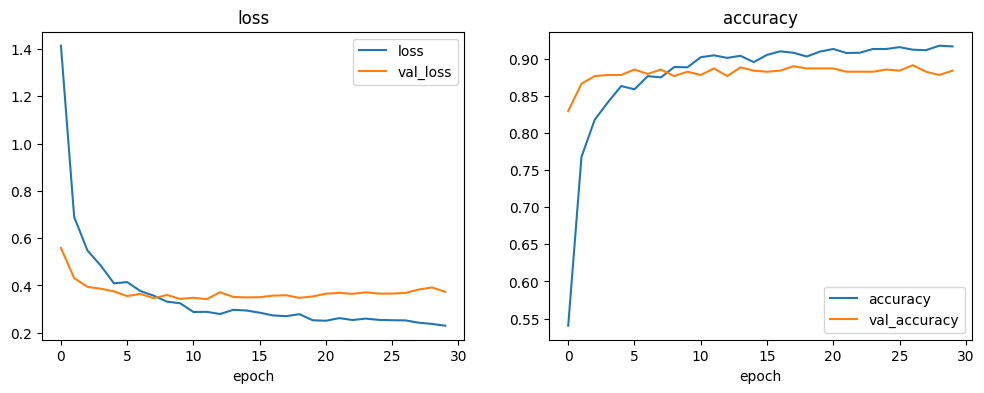

In [23]:
hist = pd.DataFrame(history_mobilenet.history)
display(hist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="loss")
hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/hasil_training/mobilenetv2.png", dpi=150, bbox_inches="tight")
plt.show()

# Custom CNN

## training

In [24]:
tf.keras.utils.set_random_seed(42)
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])
cnn_model = models.Sequential([
    layers.Input((224, 224, 3)),
    augment,
    layers.Rescaling(1/255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])
cnn_model.summary()

cnn_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
history_cnn = cnn_model.fit(train_ds, validation_data=val_ds, epochs=200)

cnn_model.save("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/model/custom_cnn.keras")
pd.DataFrame(history_cnn.history).to_csv("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/model/csv/history_cnn.csv", index=False)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,538 (369.29 KB)

 Trainable params: 94,538 (369.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.1703 - loss: 2.2150 - val_accuracy: 0.1971 - val_loss: 2.1775
Epoch 2/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.2158 - loss: 2.1369 - val_accuracy: 0.1971 - val_loss: 2.1167
Epoch 3/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.2479 - loss: 2.0650 - val_accuracy: 0.2926 - val_loss: 2.0584
Epoch 4/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 89ms/step - accuracy: 0.2845 - loss: 2.0131 - val_accuracy: 0.3221 - val_loss: 1.9730
Epoch 5/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.3050 - loss: 1.9637 - val_accuracy: 0.3941 - val_loss: 1.9673
Epoch 6/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - accuracy: 0.3278 - loss: 1.9411 - val_accuracy: 0.3176 - val_loss: 1.9603
Epoch 7/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.3233 - loss: 1.9251 - val_accuracy: 0.3471 - val_loss: 1.9405
Epoch 8/200
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - accuracy: 0.3479 - loss: 1.874

## hasil training

,accuracy,loss,val_accuracy,val_loss
0,0.170347,2.215042,0.197059,2.177479
1,0.215773,2.136877,0.197059,2.116673
2,0.247950,2.064954,0.292647,2.058367
3,0.284543,2.013103,0.322059,1.972974
4,0.305047,1.963711,0.394118,1.967338
...,...,...,...,...
195,0.696530,0.860427,0.591176,1.558321
196,0.716404,0.851417,0.613235,1.463671
197,0.712618,0.849578,0.607353,1.496280
198,0.702208,0.864186,0.611765,1.470677


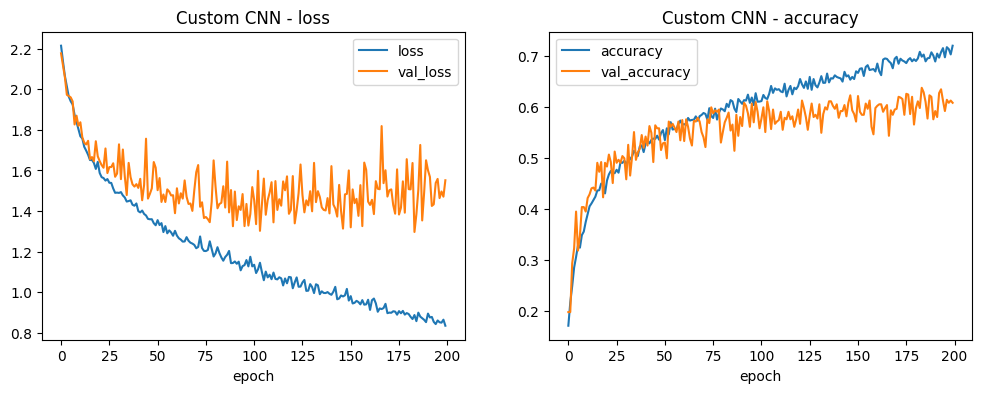

In [25]:
hist_cnn = pd.DataFrame(history_cnn.history)
display(hist_cnn)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist_cnn[["loss", "val_loss"]].plot(ax=axes[0], title="Custom CNN - loss")
hist_cnn[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Custom CNN - accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/hasil_training/custom_cnn.png", dpi=150, bbox_inches="tight")
plt.show()

# Testing

In [26]:
test_result = test_part.copy()
y_true = test_result["label"].values

## Custom Cnn

In [27]:
test_loss_cnn, test_acc_cnn = cnn_model.evaluate(test_ds)

probs_cnn = cnn_model.predict(test_ds)

test_result["pred_cnn"] = probs_cnn.argmax(axis=1)
test_result["conf_cnn"] = probs_cnn.max(axis=1)

y_pred_cnn = test_result["pred_cnn"].values

print("rata rata CNN:", (y_true == y_pred_cnn).mean())

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.5853 - loss: 1.5381
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step
rata rata CNN: 0.5852941176470589


## MobileNetV2

In [28]:
test_loss_mnet, test_acc_mnet = mobilenet_model.evaluate(test_ds)

probs_mnet = mobilenet_model.predict(test_ds)

test_result["pred_mnet"] = probs_mnet.argmax(axis=1)
test_result["conf_mnet"] = probs_mnet.max(axis=1)

y_pred_mobilenet = test_result["pred_mnet"].values

print("rata rata MobileNetV2:", (y_true == y_pred_mobilenet).mean())

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.9088 - loss: 0.3528
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step
rata rata MobileNetV2: 0.9088235294117647


# Evaluasi

## final model (overfitting check)

### Custom CNN

100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.7192 - loss: 0.8935
Custom CNN - train acc : 0.7192 | test acc : 0.5853
Custom CNN - train loss: 0.8935 | test loss: 1.5381


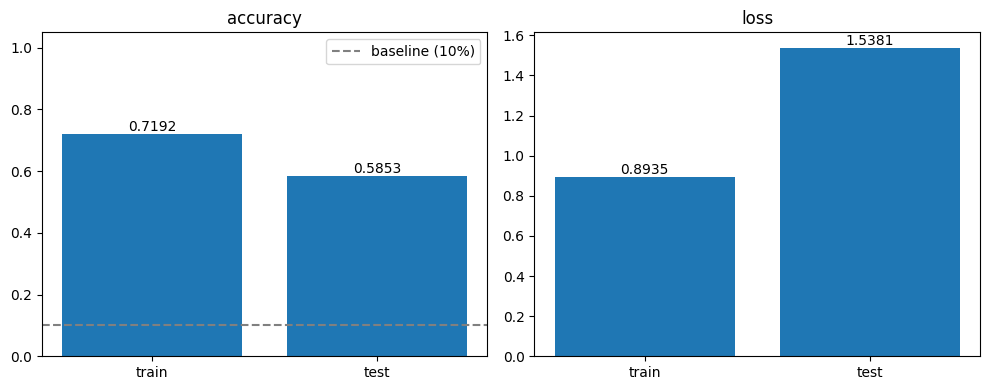

In [29]:
train_loss_cnn, train_acc_cnn = cnn_model.evaluate(train_ds)
print("Custom CNN - train acc :", round(train_acc_cnn, 4), "| test acc :", round(test_acc_cnn, 4))
print("Custom CNN - train loss:", round(train_loss_cnn, 4), "| test loss:", round(test_loss_cnn, 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

bars = axes[0].bar(["train", "test"], [train_acc_cnn, test_acc_cnn])
axes[0].bar_label(bars, fmt="%.4f")
axes[0].set_ylim(0, 1.05)
axes[0].axhline(0.1, color="gray", linestyle="--", label="baseline (10%)")
axes[0].set_title("accuracy")
axes[0].legend()

bars = axes[1].bar(["train", "test"], [train_loss_cnn, test_loss_cnn])
axes[1].bar_label(bars, fmt="%.4f")
axes[1].set_title("loss")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/final_model_CNN.png", dpi=150, bbox_inches="tight")
plt.show()

### MobileNetV2

100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.9685 - loss: 0.1092
MobileNetV2 - train acc : 0.9685 | test acc : 0.9088
MobileNetV2 - train loss: 0.1092 | test loss: 0.3528


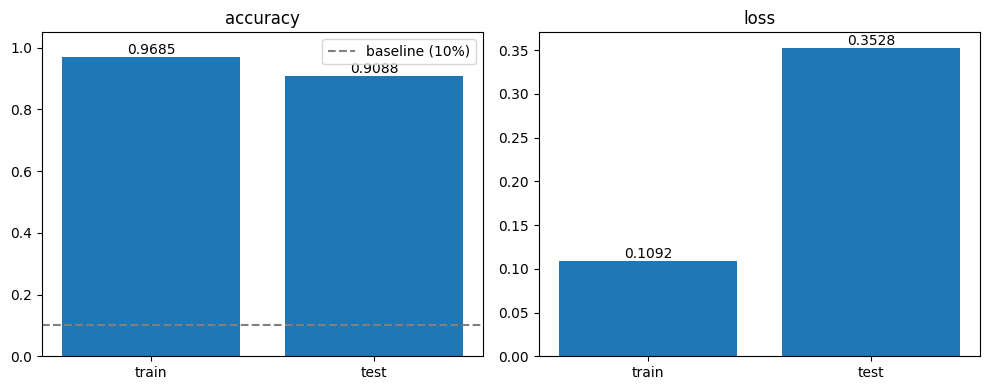

In [30]:
train_loss_mnet, train_acc_mnet = mobilenet_model.evaluate(train_ds)
print("MobileNetV2 - train acc :", round(train_acc_mnet, 4), "| test acc :", round(test_acc_mnet, 4))
print("MobileNetV2 - train loss:", round(train_loss_mnet, 4), "| test loss:", round(test_loss_mnet, 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

bars = axes[0].bar(["train", "test"], [train_acc_mnet, test_acc_mnet])
axes[0].bar_label(bars, fmt="%.4f")
axes[0].set_ylim(0, 1.05)
axes[0].axhline(0.1, color="gray", linestyle="--", label="baseline (10%)")
axes[0].set_title("accuracy")
axes[0].legend()

bars = axes[1].bar(["train", "test"], [train_loss_mnet, test_loss_mnet])
axes[1].bar_label(bars, fmt="%.4f")
axes[1].set_title("loss")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/final_model_MobileNetV2.png", dpi=150, bbox_inches="tight")
plt.show()


## Perbadingan 2 Model

,train_acc,test_acc,train_loss,test_loss,n_wrong,gap_acc
Custom CNN,0.7192,0.5853,0.8935,1.5381,282,0.1339
MobileNetV2,0.9685,0.9088,0.1092,0.3528,62,0.0596


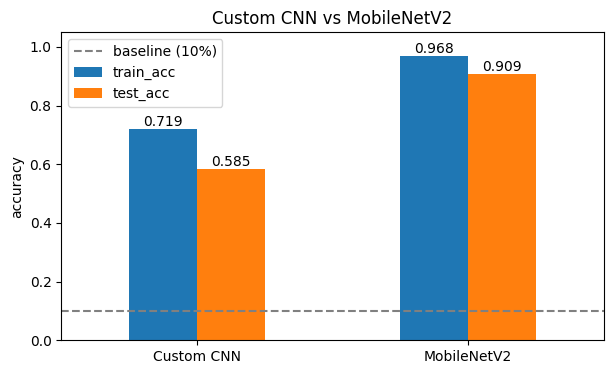

In [31]:
results = pd.DataFrame({
    "train_acc":  [train_acc_cnn, train_acc_mnet],
    "test_acc":   [test_acc_cnn, test_acc_mnet],
    "train_loss": [train_loss_cnn, train_loss_mnet],
    "test_loss":  [test_loss_cnn, test_loss_mnet],
    "n_wrong":    [int((y_true != y_pred_cnn).sum()), int((y_true != y_pred_mobilenet).sum())],
}, index=["Custom CNN", "MobileNetV2"])
results["gap_acc"] = results["train_acc"] - results["test_acc"]
display(results.round(4))
results.round(4).to_csv("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/csv/perbandingan_model.csv")

ax = results[["train_acc", "test_acc"]].plot(kind="bar", figsize=(7, 4), rot=0)
ax.axhline(0.1, color="gray", linestyle="--", label="baseline (10%)")
ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy")
ax.set_title("Custom CNN vs MobileNetV2")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
ax.legend()
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/perbandingan_model.png",
            dpi=150, bbox_inches="tight")
plt.show()

## Confusion Matrix

### Custom CNN

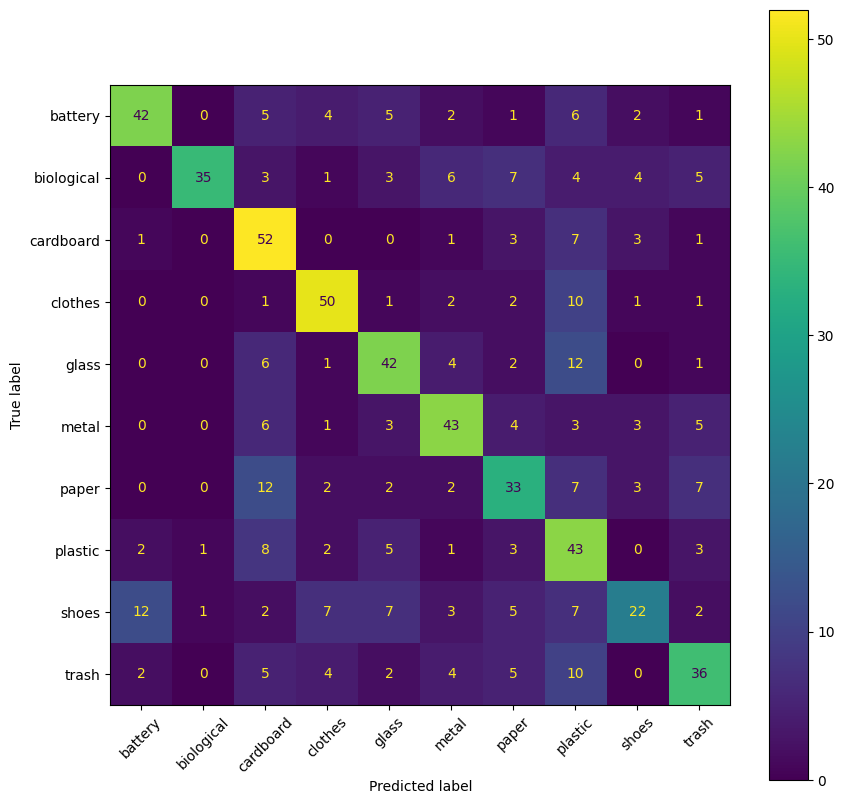

In [32]:

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred_cnn),
                       display_labels=class_names).plot(ax=ax, xticks_rotation=45)
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/confusion_matrix_cnn.png", dpi=150, bbox_inches="tight")
plt.show()

### MobileNetV2

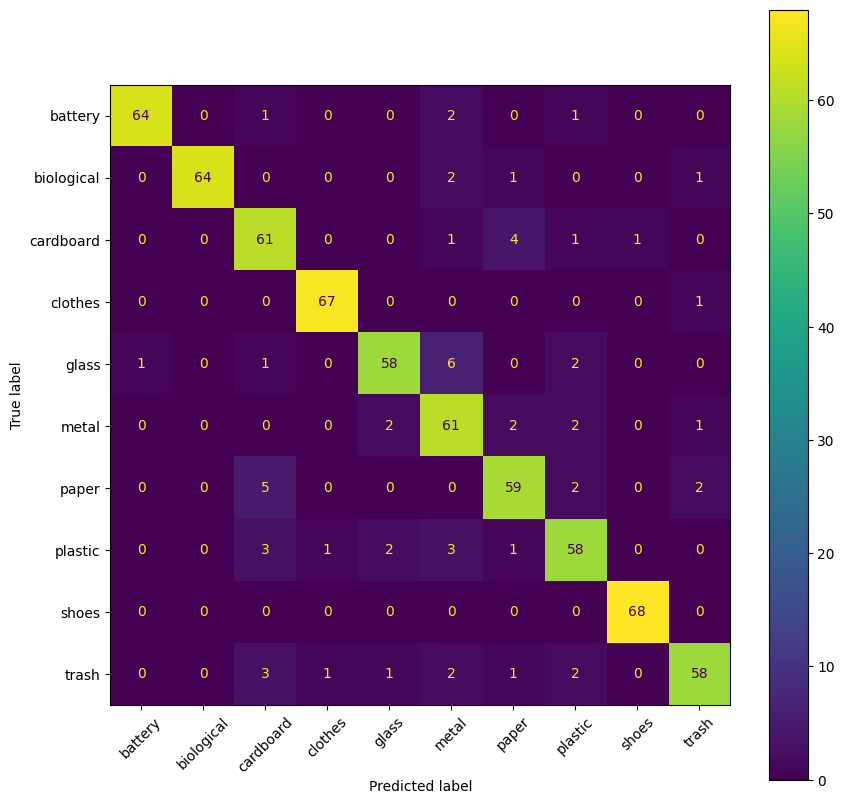

In [33]:
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred_mobilenet),
                       display_labels=class_names).plot(ax=ax, xticks_rotation=45)
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/confusion_matrix_MobileNetV2.png", dpi=150, bbox_inches="tight")
plt.show()

## Gambar yang salah ditebak model

In [34]:
def show_predictions(data, pred_col, conf_col, title, n_cols=6):
    n_rows = math.ceil(len(data) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3.3 * n_rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, data.iterrows()):
        ax.imshow(Image.open(row["path"]), cmap="gray")
        pred_name = class_names[row[pred_col]]
        ax.set_title(f'true: {row["class"]}\npred: {pred_name} ({row[conf_col]:.2f})', fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    return fig


### Custom CNN

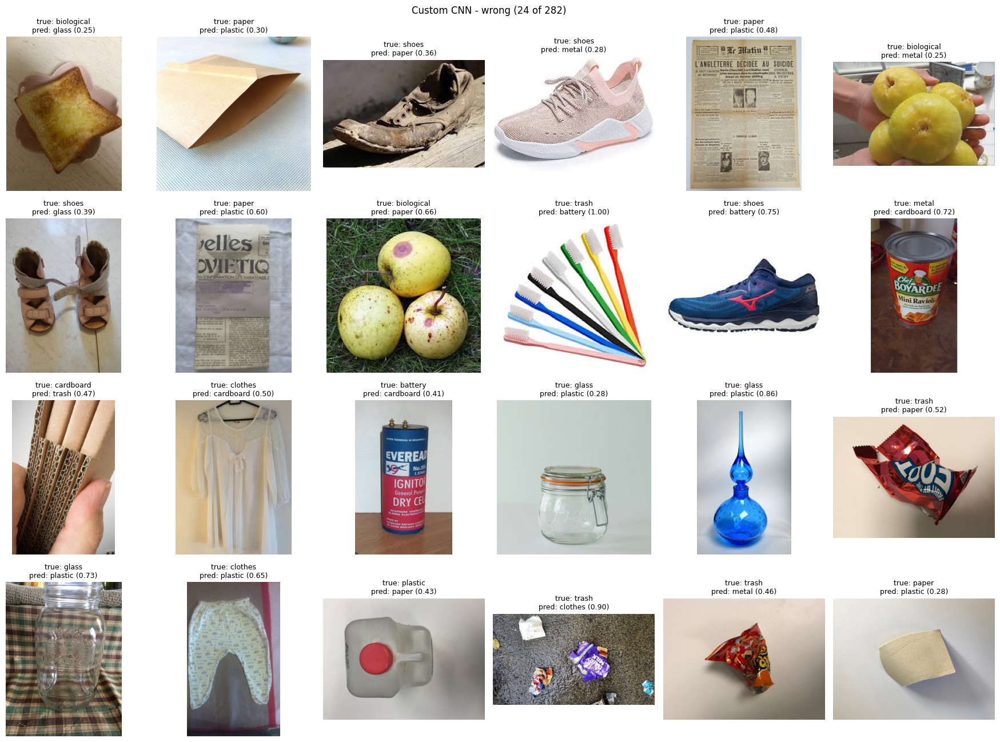

In [35]:

wrong_cnn_all = test_result[test_result["label"] != test_result["pred_cnn"]]
wrong_cnn = wrong_cnn_all.sample(min(24, len(wrong_cnn_all)), random_state=42)
fig = show_predictions(wrong_cnn, "pred_cnn", "conf_cnn",
                       f"Custom CNN - wrong ({len(wrong_cnn)} of {len(wrong_cnn_all)})")
fig.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/salah_tebak_cnn.png",
            dpi=150, bbox_inches="tight")
plt.show()

### MobileNetV2

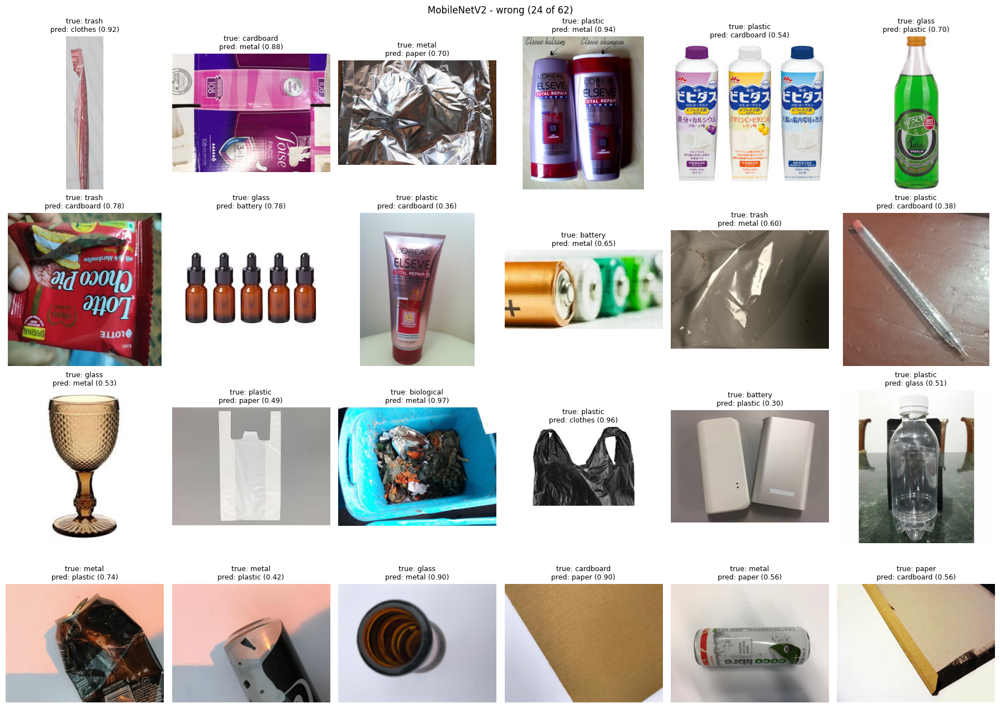

In [36]:

wrong_mnet_all = test_result[test_result["label"] != test_result["pred_mnet"]]
wrong_mnet = wrong_mnet_all.sample(min(24, len(wrong_mnet_all)), random_state=42)
fig = show_predictions(wrong_mnet, "pred_mnet", "conf_mnet", f"MobileNetV2 - wrong ({len(wrong_mnet)} of {len(wrong_mnet_all)})")
plt.savefig("/content/drive/MyDrive/Kuliah/UTS_AI_garbage/eval/salah_tebak_MobileNetV2.png", dpi=150, bbox_inches="tight")
plt.show()